In [363]:
import pandas as pd
import glob
import numpy as np
import matplotlib.pyplot as plt

## Cleaning the DF's
Currently, we have 6 data frames across various years; we want to combine each of the data frames into one large data frame. Before that we have to do conversions on the "Date" columns and also add new
columns to see if Atletico-MG won or lost.



In [364]:
#Read all of the CSV's in data and make combine into one large DF for easier analysis
csv_files = glob.glob("data/*[0-9][0-9]-[0-9][0-9].csv")
dfs = []
for file in csv_files:
    season = file.replace(".csv", "").replace("data\\", "")
    df_temp = pd.read_csv(file)
    df_temp["Season"] = season
    dfs.append(df_temp)    


In [365]:
df = pd.concat(dfs)

In [366]:
df.head()

,Date,Home Team,Away Team,Score,Time,Competition,Season
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21


In [367]:
df.tail()

,Date,Home Team,Away Team,Score,Time,Competition,Season
68,"Wed, Nov 5",Atlético-MG,Bahia,3 - 0,FT,Brazilian Serie A,2025-26
69,"Wed, Oct 15",Atlético-MG,Cruzeiro,1 - 1,FT,Brazilian Serie A,2025-26
70,"Wed, Oct 8",Atlético-MG,Sport,3 - 1,FT,Brazilian Serie A,2025-26
71,"Wed, Sep 17",Bolívar,Atlético-MG,2 - 2,FT,CONMEBOL Sudamericana,2025-26
72,"Wed, Sep 24",Atlético-MG,Bolívar,1 - 0,FT,CONMEBOL Sudamericana,2025-26


In [368]:
#Rename columns for consistancy 
df.columns = [
    "Date",
    "HomeTeam",
    "AwayTeam",
    "Score",
    "Status",
    "Competition",
    "Season"
]

In [369]:
#Extarct numerical values for the away and home goals. Used for training later
df["HomeGoals"] = pd.to_numeric(df["Score"].str[0])
df["AwayGoals"] = pd.to_numeric(df["Score"].str[-1])

In [370]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1


In [371]:
df.info()

<class 'pandas.DataFrame'>
Index: 410 entries, 0 to 72
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Date         410 non-null    str  
 1   HomeTeam     410 non-null    str  
 2   AwayTeam     410 non-null    str  
 3   Score        410 non-null    str  
 4   Status       410 non-null    str  
 5   Competition  410 non-null    str  
 6   Season       410 non-null    str  
 7   HomeGoals    410 non-null    int64
 8   AwayGoals    410 non-null    int64
dtypes: int64(2), str(7)
memory usage: 32.0 KB


In [372]:
#Create a column that says whether Galo (nickname for Atletico-MG) was at home or not. 
df["IsHome"] = (df["HomeTeam"].str.contains("Atlético-MG"))

In [373]:
df.head(10)

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0,False
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1,False
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0,False
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1,False
5,"Sat, Dec 26",Atlético-MG,Coritiba,2 - 0,FT,Brazilian Serie A,2020-21,2,0,True
6,"Sat, Feb 13",Atlético-MG,Bahia,1 - 1,FT,Brazilian Serie A,2020-21,1,1,True
7,"Sat, Jan 23",Vasco da Gama,Atlético-MG,3 - 2,FT,Brazilian Serie A,2020-21,3,2,False
8,"Sat, Mar 14",Villa Nova-MG,Atlético-MG,1 - 3,FT,Brazilian Campeonato Mineiro,2020-21,1,3,False
9,"Sat, Mar 7",Atlético-MG,Cruzeiro,2 - 1,FT,Brazilian Campeonato Mineiro,2020-21,2,1,True


In [374]:
df["GaloGoals"] = df["HomeGoals"].where(df["IsHome"] == 1, df["AwayGoals"])
df["OppGoals"] = df["AwayGoals"].where(df["IsHome"] == 1, df["HomeGoals"])

In [375]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False,2,2
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0,False,0,3
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1,False,1,3
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0,False,0,1
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1,False,1,0


In [376]:
conditions = [
    df["GaloGoals"] > df["OppGoals"],
    df["GaloGoals"] < df["OppGoals"]
]
choices = ["Win", "Loss"]

In [377]:
df["WinLossDraw"] = np.select(conditions, choices, default="Draw")

In [378]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals,WinLossDraw
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False,2,2,Draw
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0,False,0,3,Loss
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1,False,1,3,Loss
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0,False,0,1,Loss
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1,False,1,0,Win


## Get win rate for each type of competitions, at home and away and overall


In [379]:
#Overall win rate
result_pct = df['WinLossDraw'].value_counts(normalize=True)

In [380]:
print(result_pct)

WinLossDraw
Win     0.512195
Draw    0.265854
Loss    0.221951
Name: proportion, dtype: float64


In [381]:
win_pct = result_pct.get('Win')
print(win_pct)

0.5121951219512195


In [382]:
draw_pct = result_pct.get('Draw')
print(draw_pct)

0.2658536585365854


In [383]:
loss_pct = result_pct.get('Loss')
print(loss_pct)

0.22195121951219512


In [384]:
#Win rate while Galo is at home
home_games = df[df['IsHome']]
home_win_pct = (home_games['WinLossDraw'] == 'Win').mean()
print(home_win_pct)

0.6439024390243903


In [385]:
#Calculating the win rate per competition
comp_summary = (
    df.groupby("Competition").agg(
        total_games=("WinLossDraw", "count"),
        wins=("WinLossDraw", lambda x: (x == "Win").sum()),
        draws=("WinLossDraw", lambda x: (x == "Draw").sum()),
        losses=("WinLossDraw", lambda x: (x == "Loss").sum()),
        win_rate=("WinLossDraw", lambda x: (x == "Win").mean())
    ).sort_values(by="total_games", ascending=False)
)
comp_summary[['total_games', 'wins', 'draws', 'losses', 'win_rate']]

,total_games,wins,draws,losses,win_rate
Competition,,,,,
Brazilian Serie A,227,102,62,63,0.449339
Brazilian Campeonato Mineiro,80,54,17,9,0.675000
CONMEBOL Libertadores,47,24,16,7,0.510638
Copa do Brasil,38,22,7,9,0.578947
CONMEBOL Sudamericana,17,8,6,3,0.470588
Brazilian Supercopa Rei,1,0,1,0,0.000000


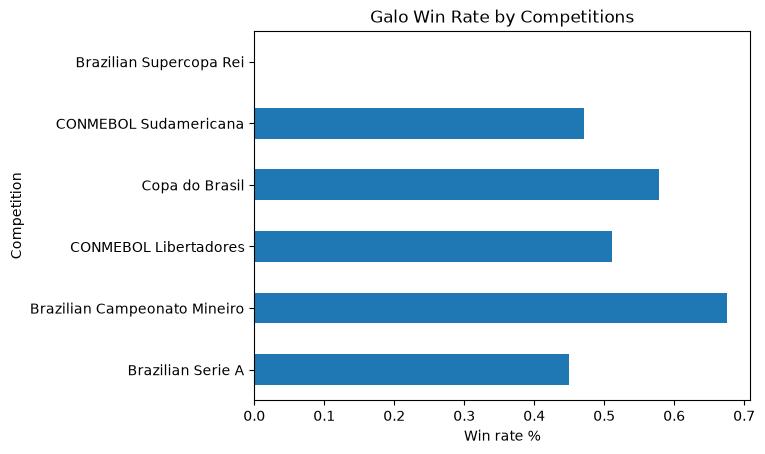

In [386]:
#Graph for overall winrate
comp_summary['win_rate'].plot(
    kind='barh',
    title = 'Galo Win Rate by Competitions'
)
plt.xlabel('Win rate %')
plt.show()

In [387]:
#Graph for wins, losses and draws
comp_pct = (
    df.groupby('Competition')['WinLossDraw'].value_counts(normalize=True).unstack().fillna(0))

comp_pct.head()

WinLossDraw,Draw,Loss,Win
Competition,,,
Brazilian Campeonato Mineiro,0.212500,0.112500,0.675000
Brazilian Serie A,0.273128,0.277533,0.449339
Brazilian Supercopa Rei,1.000000,0.000000,0.000000
CONMEBOL Libertadores,0.340426,0.148936,0.510638
CONMEBOL Sudamericana,0.352941,0.176471,0.470588


In [388]:
#Reorder columns logically
comp_pct = comp_pct[['Win', 'Draw', 'Loss']]

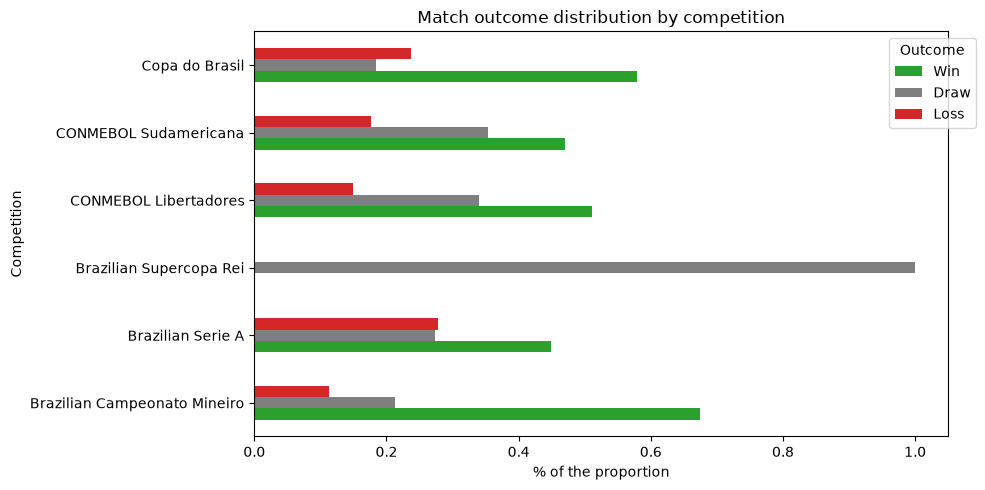

In [389]:
comp_pct.plot(
    kind='barh',
    figsize=(10,5),
    stacked=False,
    color=['#2ca02c', '#7f7f7f', '#d62728']
)
plt.title('Match outcome distribution by competition')
plt.xlabel('% of the proportion')
plt.legend(title='Outcome', bbox_to_anchor=(1.05,1))
plt.tight_layout()
plt.show()

In [390]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals,WinLossDraw
0,"Mon, Jan 11",Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False,2,2,Draw
1,"Mon, Nov 2",Palmeiras,Atlético-MG,3 - 0,FT,Brazilian Serie A,2020-21,3,0,False,0,3,Loss
2,"Mon, Oct 19",Bahia,Atlético-MG,3 - 1,FT,Brazilian Serie A,2020-21,3,1,False,1,3,Loss
3,"Sat, Aug 22",Internacional,Atlético-MG,1 - 0,FT,Brazilian Serie A,2020-21,1,0,False,0,1,Loss
4,"Sat, Dec 12",Athletico Paranaense,Atlético-MG,0 - 1,FT,Brazilian Serie A,2020-21,0,1,False,1,0,Win


In [391]:
#Grouping by type of competition and if Galo is at home.
home_away_split = df.groupby(['Competition', 'IsHome'])['WinLossDraw'].apply(lambda x: (x == 'Win').mean()).unstack()
home_away_split.columns = ['Away Win %', 'Home Wil %']


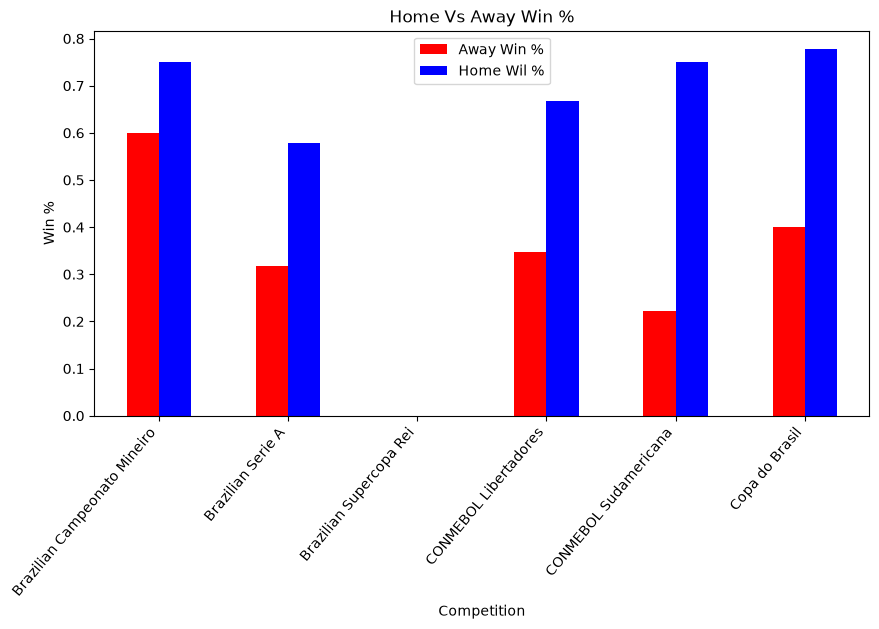

In [392]:

home_away_split.plot(
    kind='bar',
    figsize=(10,5),
    color=['red','blue']
)
plt.title('Home Vs Away Win %')
plt.ylabel('Win %')
plt.xticks(rotation=50, ha='right')
plt.show()


In [393]:
# Extract the starting year from '2020-21' -> '2020'
df['Year'] = df['Season'].str.split('-').str[0]

# Combine raw Date string with the 4-digit Year
df['Date_Full'] = df['Date'].astype(str) + '-' + df['Year'].astype(str)
df['Date'] = pd.to_datetime(df['Date_Full'], format='mixed', errors='coerce')

# Now sort chronologically across years
df = df.sort_values('Date').reset_index(drop=True)
df['DaysOfRest'] = df['Date'].diff().dt.days.fillna(7)
df.tail()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals,WinLossDraw,Year,Date_Full,DaysOfRest
405,2025-11-22,Lanús,Atlético-MG,0 - 0,FT-Pens,CONMEBOL Sudamericana,2025-26,0,0,False,0,0,Draw,2025,"Sat, Nov 22-2025",6.0
406,2025-11-25,Atlético-MG,Flamengo,1 - 1,FT,Brazilian Serie A,2025-26,1,1,True,1,1,Draw,2025,"Tue, Nov 25-2025",3.0
407,2025-11-30,Fortaleza,Atlético-MG,1 - 0,FT,Brazilian Serie A,2025-26,1,0,False,0,1,Loss,2025,"Sun, Nov 30-2025",5.0
408,2025-12-03,Atlético-MG,Palmeiras,0 - 3,FT,Brazilian Serie A,2025-26,0,3,True,0,3,Loss,2025,"Wed, Dec 3-2025",3.0
409,2025-12-07,Atlético-MG,Vasco da Gama,5 - 0,FT,Brazilian Serie A,2025-26,5,0,True,5,0,Win,2025,"Sun, Dec 7-2025",4.0


In [394]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 410 entries, 0 to 409
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         410 non-null    datetime64[us]
 1   HomeTeam     410 non-null    str           
 2   AwayTeam     410 non-null    str           
 3   Score        410 non-null    str           
 4   Status       410 non-null    str           
 5   Competition  410 non-null    str           
 6   Season       410 non-null    str           
 7   HomeGoals    410 non-null    int64         
 8   AwayGoals    410 non-null    int64         
 9   IsHome       410 non-null    bool          
 10  GaloGoals    410 non-null    int64         
 11  OppGoals     410 non-null    int64         
 12  WinLossDraw  410 non-null    str           
 13  Year         410 non-null    object        
 14  Date_Full    410 non-null    str           
 15  DaysOfRest   410 non-null    float64       
dtypes: bool(1), datetim

## Season by season trajectory 
### We want to plot how succesful Galo was in Serie A for each season. 


In [395]:
df.head()

,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals,WinLossDraw,Year,Date_Full,DaysOfRest
0,2020-01-11,Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False,2,2,Draw,2020,"Mon, Jan 11-2020",7.0
1,2020-01-17,Atlético-MG,Atlético Goianiense,3 - 1,FT,Brazilian Serie A,2020-21,3,1,True,3,1,Win,2020,"Sun, Jan 17-2020",6.0
2,2020-01-20,Grêmio,Atlético-MG,1 - 1,FT,Brazilian Serie A,2020-21,1,1,False,1,1,Draw,2020,"Wed, Jan 20-2020",3.0
3,2020-01-21,Uberlândia,Atlético-MG,0 - 1,FT,Brazilian Campeonato Mineiro,2020-21,0,1,False,1,0,Win,2020,"Tue, Jan 21-2020",1.0
4,2020-01-23,Vasco da Gama,Atlético-MG,3 - 2,FT,Brazilian Serie A,2020-21,3,2,False,2,3,Loss,2020,"Sat, Jan 23-2020",2.0


In [396]:
serie_a = df[df['Competition'] == 'Brazilian Serie A']
serie_a.info()

<class 'pandas.DataFrame'>
Index: 227 entries, 0 to 409
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         227 non-null    datetime64[us]
 1   HomeTeam     227 non-null    str           
 2   AwayTeam     227 non-null    str           
 3   Score        227 non-null    str           
 4   Status       227 non-null    str           
 5   Competition  227 non-null    str           
 6   Season       227 non-null    str           
 7   HomeGoals    227 non-null    int64         
 8   AwayGoals    227 non-null    int64         
 9   IsHome       227 non-null    bool          
 10  GaloGoals    227 non-null    int64         
 11  OppGoals     227 non-null    int64         
 12  WinLossDraw  227 non-null    str           
 13  Year         227 non-null    object        
 14  Date_Full    227 non-null    str           
 15  DaysOfRest   227 non-null    float64       
dtypes: bool(1), datetime64[u

In [397]:
serie_a.value_counts()

Date        HomeTeam             AwayTeam             Score  Status  Competition        Season   HomeGoals  AwayGoals  IsHome  GaloGoals  OppGoals  WinLossDraw  Year  Date_Full         DaysOfRest
2020-01-11  Red Bull Bragantino  Atlético-MG          2 - 2  FT      Brazilian Serie A  2020-21  2          2          False   2          2         Draw         2020  Mon, Jan 11-2020  7.0           1
2020-01-17  Atlético-MG          Atlético Goianiense  3 - 1  FT      Brazilian Serie A  2020-21  3          1          True    3          1         Win          2020  Sun, Jan 17-2020  6.0           1
2020-01-20  Grêmio               Atlético-MG          1 - 1  FT      Brazilian Serie A  2020-21  1          1          False   1          1         Draw         2020  Wed, Jan 20-2020  3.0           1
2020-01-23  Vasco da Gama        Atlético-MG          3 - 2  FT      Brazilian Serie A  2020-21  3          2          False   2          3         Loss         2020  Sat, Jan 23-2020  2.0           1


In [398]:
#Extract who the opponent is
serie_a['Opponent'] = serie_a.apply(
    lambda row: row['AwayTeam'] if row['IsHome'] == 1 else row['HomeTeam'], axis=1)
serie_a.head(3)


,Date,HomeTeam,AwayTeam,Score,Status,Competition,Season,HomeGoals,AwayGoals,IsHome,GaloGoals,OppGoals,WinLossDraw,Year,Date_Full,DaysOfRest,Opponent
0,2020-01-11,Red Bull Bragantino,Atlético-MG,2 - 2,FT,Brazilian Serie A,2020-21,2,2,False,2,2,Draw,2020,"Mon, Jan 11-2020",7.0,Red Bull Bragantino
1,2020-01-17,Atlético-MG,Atlético Goianiense,3 - 1,FT,Brazilian Serie A,2020-21,3,1,True,3,1,Win,2020,"Sun, Jan 17-2020",6.0,Atlético Goianiense
2,2020-01-20,Grêmio,Atlético-MG,1 - 1,FT,Brazilian Serie A,2020-21,1,1,False,1,1,Draw,2020,"Wed, Jan 20-2020",3.0,Grêmio


In [399]:
#Group by each season and select only the WinLossDraw columns
trend = serie_a.groupby('Season')['WinLossDraw'].apply(lambda x: (x=='Win').mean())
trend.head()

Season
2020-21    0.526316
2021-22    0.675676
2022-23    0.394737
2023-24    0.500000
2024-25    0.289474
Name: WinLossDraw, dtype: float64

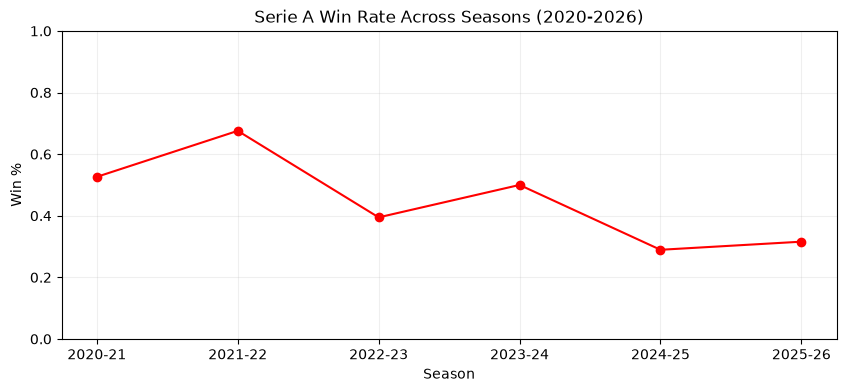

In [400]:
#Plotting the trend over the seasons
plt.figure(figsize=(10,4))
trend.plot(kind='line', marker='o', color='red')
plt.title('Serie A Win Rate Across Seasons (2020-2026)')
plt.ylabel('Win %')
plt.ylim(0, 1)
plt.xlabel('Season')
plt.grid(True, alpha=0.2)
plt.show()

## Save the plots and df's to use into our ML file


In [401]:
comp_summary.to_csv('figures/comp_summary', index=False)
df.to_csv('figures/df', index=False)
comp_pct.to_csv('figures/comp_pct', index=False)
home_away_split.to_csv('figures/home_away_split', index=False)
trend.to_csv('figures/trend', index=False)
serie_a.to_csv('figures/serie_a', index=False)

